# File 5: Rent Trends (Auckland)

## Purpose
Auckland has no free sale-price history by suburb, but it has 33 years of rent, and an Auckland-wide sale-price series from HUD's archived Urban Development `TA.csv`. This notebook is the Auckland version of Adelaide's
historical trend analysis, done on rent: the long-run trend, growth by year, the COVID shock and recovery, seasonality,
turnover, and which kinds of area led the 2020–24 rise and the cooling since.

## Inputs
| File | What |
|---|---|
| `data/rental/mbie_monthly_ta.csv` | MBIE **official** monthly figures by council, Feb 1993 – latest: new bonds lodged, active and closed bonds, median and quartile rent |
| `data/rental/mbie_quarterly_sa2_2020_2026.csv` | Raw quarterly SA2 file: lodged and closed bonds, quartile rents |
| `data/clean/rent_timeseries_by_sa2.csv` | Quarterly SA2 median rent (from `build_master.py`) |
| `data/clean/area_profiles_by_sa2.csv`, `master_flagged.csv` | Area types (File 3) and flags (File 1) |
| `data/property_prices/hud_ta_sales_rents.zip` (`TA.csv`) | HUD Urban Development dataset: quarterly median sale price, sales count and price index by council. The archived Urban Development `TA.csv` used here is **Auckland-wide** |

## Two definitions
- **Median rent** = median weekly rent of **new bonds lodged** in the period, all dwelling types. It shows what a new tenant pays, not sitting tenants.
- **Lodged / active / closed bonds**: new tenancies started / tenancies running / tenancies ended. Bond lodgement is required by law, so this is close to a census of private tenancies.

## Steps
1. Load the official monthly Auckland series, and check it against File 1's approximation
2. The long-run trend, 1993 to now
3. Growth by year
4. COVID shock and recovery
5. Seasonality: the best and worst months
6. Rental market size and turnover
7. SA2s: turnover and rent spread
8. Boom and cooling by area type
9. Sale prices next to rent (HUD, Auckland-wide)
10. Save outputs

In [1]:
# STEP 0: SETUP
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, NullFormatter

CLEAN = Path('data/clean')
VIZ = Path('visualizations'); VIZ.mkdir(exist_ok=True)

# Palette: categorical slots 1-2, single-hue sequential, orange-grey-blue diverging
BLUE, ORANGE, GREY, INK, MUTED = '#2a78d6', '#eb6834', '#b9b8b3', '#0b0b0b', '#52514e'
SEQ = 'Blues'
DIV = LinearSegmentedColormap.from_list('div', [ORANGE, '#e6e5e1', BLUE])
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GREY, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': '#ecebe8', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 10,
})
dollars = FuncFormatter(lambda v, _: f'${v/1e6:.1f}m' if v >= 1e6 else f'${v/1e3:.0f}k')
CV_TICKS = [1e5, 3e5, 5e5, 1e6, 2e6, 5e6, 1e7, 3e7]

def cv_axis(ax, lo, hi):
    ax.set_xscale('log'); ax.set_xticks([t for t in CV_TICKS if lo <= t <= hi])
    ax.xaxis.set_major_formatter(dollars); ax.xaxis.set_minor_formatter(NullFormatter())
pd.set_option('display.width', 160, 'display.max_columns', 40)

### Step 1: Load the official monthly series

In [2]:
# STEP 1: OFFICIAL AUCKLAND MONTHLY SERIES (numbers come as text with thousands commas)
raw = pd.read_csv('data/rental/mbie_monthly_ta.csv', dtype=str)
a = raw[raw.Location == 'Auckland'].copy()
num = ['Lodged Bonds', 'Active Bonds', 'Closed Bonds', 'Median Rent', 'Upper Quartile Rent', 'Lower Quartile Rent']
a[num] = a[num].apply(lambda s: pd.to_numeric(s.str.replace(',', ''), errors='coerce'))
akl = (a.assign(month=pd.to_datetime(a['Time Frame'])).set_index('month')[num]
        .rename(columns={'Lodged Bonds': 'lodged', 'Active Bonds': 'active', 'Closed Bonds': 'closed', 'Median Rent': 'median_rent',
                         'Upper Quartile Rent': 'uq_rent', 'Lower Quartile Rent': 'lq_rent'}).sort_index())
assert akl.index.is_unique and akl.median_rent.notna().all()
print(f'{len(akl)} months, {akl.index.min():%b %Y} to {akl.index.max():%b %Y} | gaps: {len(pd.date_range(akl.index.min(), akl.index.max(), freq="MS")) - len(akl)}')

# Check File 1's approximation (bond-weighted average of SA2 medians) against the official median, same quarter
ts = pd.read_csv(CLEAN / 'rent_timeseries_by_sa2.csv', parse_dates=['quarter'])
latest_q = ts.quarter.max()
approx = ts[ts.quarter == latest_q].pipe(lambda d: np.average(d.median_rent, weights=d.active_bonds))
official = akl.loc[latest_q:latest_q + pd.DateOffset(months=2), 'median_rent'].mean()
print(f'Quarter starting {latest_q:%b %Y}: official median ${official:.0f}/wk, File 1 approximation ${approx:.0f}/wk ({approx - official:+.0f})')
akl.tail(3)

404 months, Feb 1993 to Sep 2026 | gaps: 0
Quarter starting Jul 2026: official median $643/wk, File 1 approximation $662/wk (+18)


,lodged,active,closed,median_rent,uq_rent,lq_rent
month,,,,,,
2026-07-01,5835,171024,4224,640,750,520
2026-08-01,4815,171900,3750,650,760,540
2026-09-01,4653,172140,4176,640,750,530


**Reading this:** the series has no gaps (Feb 1993 to Sep 2026). For Jul–Sep 2026 the official figure is **\$643/wk**, the average of the three monthly medians (\$640, \$650, \$640), while File 1's
approximation gives \$662, about \$18 (3%) too high. The approximation is a bond-weighted average of SA2 *medians*, and an
average of medians is not the median of all bonds: the dearer SA2s with many bonds pull it up.
**Decision:** quote the official figure for "Auckland", and keep SA2 medians for comparing areas with each other.

### Step 2: The long-run trend

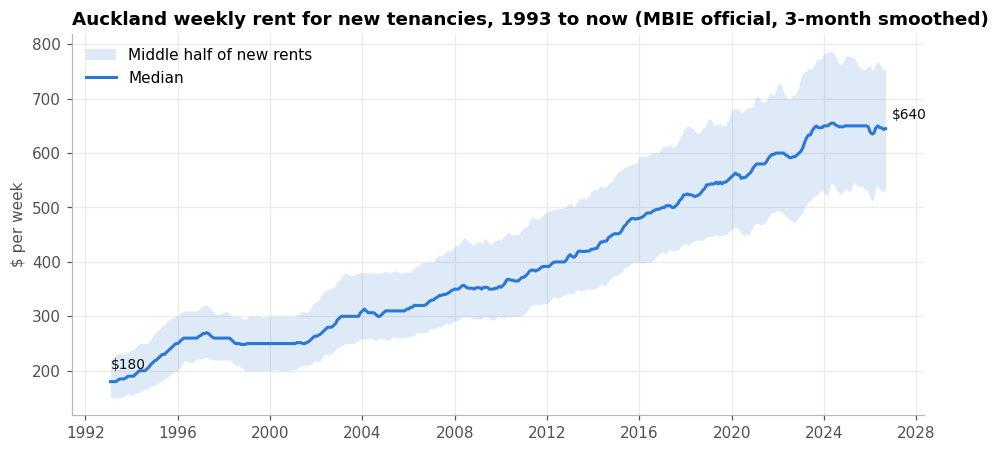

1994 to 2025: $200 -> $650/wk, 3.9% a year
Quartile spread (upper / lower): 1.52 in 1994, 1.43 in 2025


In [3]:
# STEP 2: LONG-RUN TREND with the middle half of new rents (lower to upper quartile) as a band
r3 = akl[['median_rent', 'lq_rent', 'uq_rent']].rolling(3, center=True, min_periods=1).mean()   # 3-month smoothing of month-to-month noise
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.fill_between(r3.index, r3.lq_rent, r3.uq_rent, color=BLUE, alpha=0.15, linewidth=0, label='Middle half of new rents')
ax.plot(r3.index, r3.median_rent, color=BLUE, lw=2, label='Median')
for when in [akl.index.min(), akl.index.max()]:
    v = akl.loc[when, 'median_rent']
    ax.annotate(f'${v:.0f}', (when, v), xytext=(4 if when == akl.index.max() else 0, 8), textcoords='offset points', fontsize=9, color=INK)
ax.legend(frameon=False, loc='upper left')
ax.set(title='Auckland weekly rent for new tenancies, 1993 to now (MBIE official, 3-month smoothed)', ylabel='$ per week')
fig.savefig(VIZ / '05_rent_long_run.png'); plt.show()

yr = akl.resample('YE').agg({'median_rent': 'mean', 'lq_rent': 'mean', 'uq_rent': 'mean', 'lodged': 'sum'})
full = yr[(yr.index.year > akl.index.min().year) & (yr.index.year < akl.index.max().year)]   # complete calendar years only
n = full.index.year[-1] - full.index.year[0]
print(f'{full.index.year[0]} to {full.index.year[-1]}: ${full.median_rent.iloc[0]:.0f} -> ${full.median_rent.iloc[-1]:.0f}/wk, '
      f'{100*((full.median_rent.iloc[-1]/full.median_rent.iloc[0])**(1/n)-1):.1f}% a year')
print(f'Quartile spread (upper / lower): {full.uq_rent.iloc[0]/full.lq_rent.iloc[0]:.2f} in {full.index.year[0]}, {full.uq_rent.iloc[-1]/full.lq_rent.iloc[-1]:.2f} in {full.index.year[-1]}')

### Step 3: Growth by year

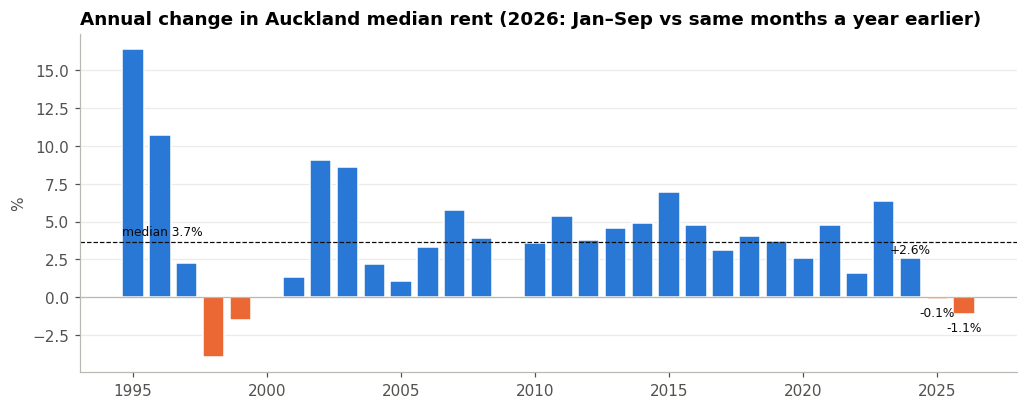

Fastest years: 1995 (+16.4%), 1996 (+10.7%), 2002 (+9.0%), 2003 (+8.6%)
Years rent fell: 1998 (-3.9%), 1999 (-1.5%), 2025 (-0.1%), 2026 (-1.1%)


In [4]:
# STEP 3: ANNUAL GROWTH = change in the calendar-year average median rent (the latest, partial year compared on the same months)
g = 100 * full.median_rent.pct_change()
last_m = akl.index.max().month
ytd = akl[akl.index.year == akl.index.max().year].median_rent.mean()
same_last = akl[(akl.index.year == akl.index.max().year - 1) & (akl.index.month <= last_m)].median_rent.mean()
g.loc[pd.Timestamp(f'{akl.index.max().year}-12-31')] = 100 * (ytd / same_last - 1)
g = g.dropna(); g.index = g.index.year

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(g.index, g.values, color=np.where(g > 0, BLUE, ORANGE), width=0.8, edgecolor='white', linewidth=1)
ax.axhline(0, color=GREY, lw=0.8); ax.axhline(g.median(), color=INK, lw=0.8, ls='--')
ax.annotate(f'median {g.median():.1f}%', (g.index[0] - 0.4, g.median()), xytext=(0, 4), textcoords='offset points', fontsize=8, color=INK)
for yv in g.index[-3:]:
    ax.annotate(f'{g[yv]:+.1f}%', (yv, g[yv]), xytext=(0, 3 if g[yv] >= 0 else -11), textcoords='offset points', ha='center', fontsize=8, color=INK)
ax.grid(axis='x', visible=False)
ax.set(title=f'Annual change in Auckland median rent ({g.index[-1]}: Jan–{akl.index.max():%b} vs same months a year earlier)', ylabel='%')
fig.savefig(VIZ / '05_rent_growth_by_year.png'); plt.show()
print('Fastest years:', ', '.join(f'{y} ({v:+.1f}%)' for y, v in g.nlargest(4).items()))
print('Years rent fell:', ', '.join(f'{y} ({v:+.1f}%)' for y, v in g[g.round(1) < 0].items()) or 'none')

**Reading this:**
- Rent rose almost every year for 33 years: **\$200 to \$650/wk from 1994 to 2025, 3.9% a year**, with a median year of +3.7%.
- The only falls were 1998–99 (the late-90s slowdown that followed the mid-90s immigration surge) and **now: 2025 −0.1% and 2026 so far −1.1%.**
  That is the first back-to-back fall in 27 years.
- 2023 (+6.3%) was the last strong year, after the border reopened.
- File 2's 10-year figure (3.0% a year) is lower than the 33-year one, because the last decade includes this flat patch.

*Caveat:* this is rent on **new** tenancies. Sitting tenants' rents move more slowly, so this series leads rather than describes what most renters pay.

### Step 4: COVID shock and recovery

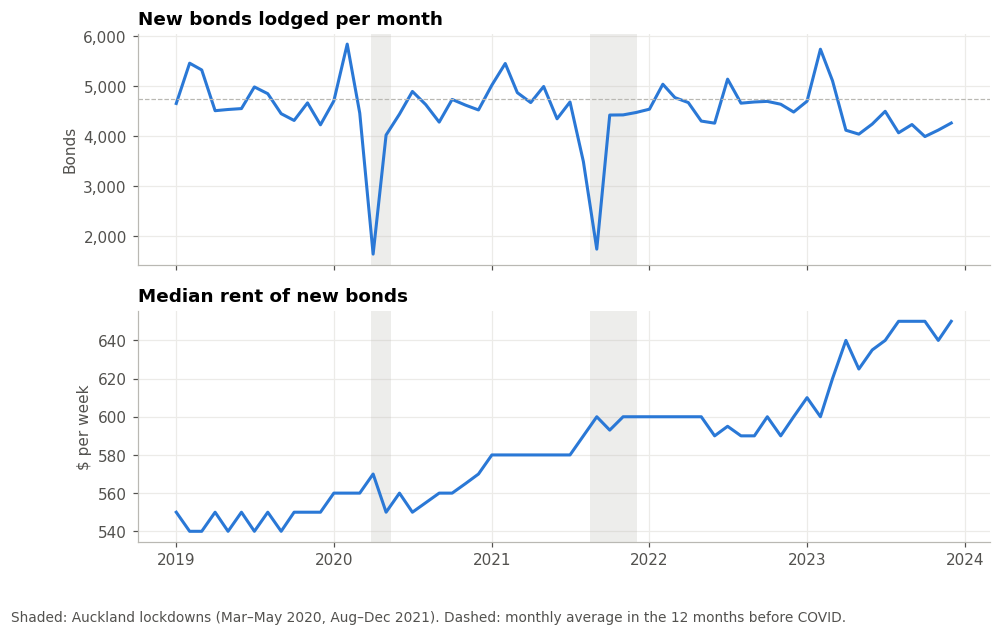

April 2020 lodgements: 1,647 vs 4,745 a month before COVID (-65%)
  Feb 2020: $560/wk
  Apr 2020: $570/wk
  Dec 2020: $570/wk
  Dec 2021: $600/wk
  Dec 2022: $600/wk
  Dec 2023: $650/wk


In [5]:
# STEP 4: COVID. Two panels, shared time axis (two measures, two scales, so never one dual-axis chart)
c = akl.loc['2019-01':'2023-12']
base = akl.loc['2019-03':'2020-02']   # the 12 months before the first lockdown
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(c.index, c.lodged, color=BLUE, lw=2)
axes[0].axhline(base.lodged.mean(), color=GREY, lw=0.8, ls='--')
axes[0].set(title='New bonds lodged per month', ylabel='Bonds')
axes[1].plot(c.index, c.median_rent, color=BLUE, lw=2)
axes[1].set(title='Median rent of new bonds', ylabel='$ per week')
for ax in axes:
    for start, end in [('2020-03-26', '2020-05-13'), ('2021-08-17', '2021-12-02')]:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=GREY, alpha=0.25, linewidth=0)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
fig.text(0.01, -0.01, 'Shaded: Auckland lockdowns (Mar–May 2020, Aug–Dec 2021). Dashed: monthly average in the 12 months before COVID.', color=MUTED, fontsize=9)
fig.savefig(VIZ / '05_covid.png'); plt.show()

apr20 = akl.loc['2020-04']
print(f'April 2020 lodgements: {apr20.lodged.iloc[0]:,.0f} vs {base.lodged.mean():,.0f} a month before COVID ({100*(apr20.lodged.iloc[0]/base.lodged.mean()-1):+.0f}%)')
for mth in ['2020-02', '2020-04', '2020-12', '2021-12', '2022-12', '2023-12']:
    print(f'  {pd.Timestamp(mth):%b %Y}: ${akl.loc[mth, "median_rent"].iloc[0]:.0f}/wk')

**Reading this:**
- **Volume took the big hit; price barely moved.** New bonds fell 65% in April 2020 (1,647 against 4,745 a month before COVID) and again in the
  August 2021 lockdown. Both times they bounced back within about a month: moves were put off, not cancelled.
- **Rent dipped only briefly:** \$570 in April 2020 to \$550 in May, and \$560 in June to \$550 in July. It was back to
  \$570 by December 2020 and \$600 by December 2021.
- With the border shut, rent then **stalled at about \$600 through 2022**. The jump to \$650 came in 2023, after the border reopened.

**Lesson:** shocks show up in volume first. Over the medium term, price followed migration, not lockdowns.

### Step 5: Seasonality

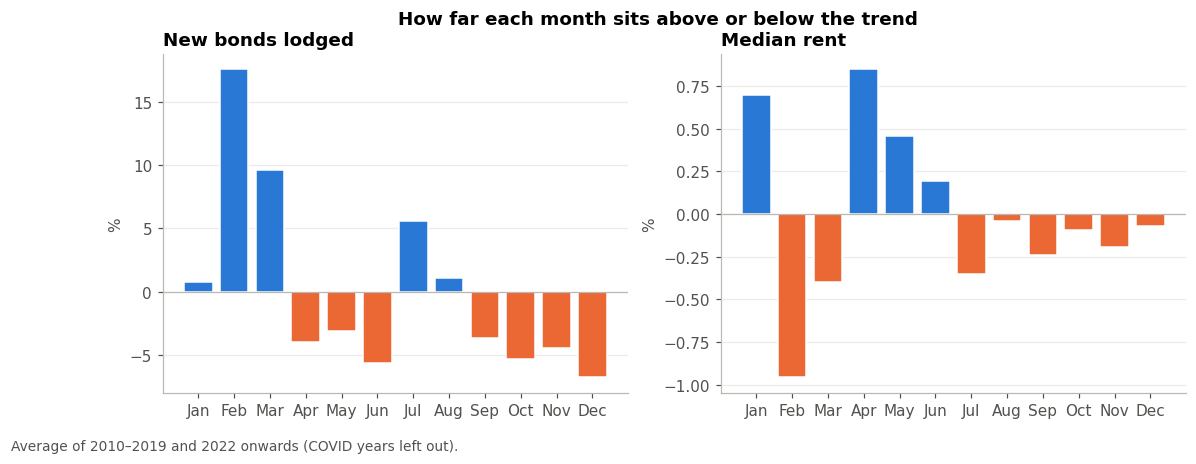

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
New bonds lodged,0.7,17.5,9.6,-4.0,-3.1,-5.7,5.6,1.1,-3.7,-5.3,-4.5,-6.8
Median rent,0.7,-1.0,-0.4,0.8,0.5,0.2,-0.4,-0.0,-0.2,-0.1,-0.2,-0.1


In [6]:
# STEP 5: SEASONALITY by ratio to a centred 12-month moving average (the classic decomposition, done by hand):
# each month / its 2x12 moving average shows how far that month sits above or below the underlying trend.
def seasonal(s):
    trend = s.rolling(12, center=True).mean().rolling(2).mean().shift(-1)   # 2x12 centred MA
    ratio = 100 * (s / trend - 1)
    ratio = ratio[(ratio.index.year >= 2010) & ~ratio.index.year.isin([2020, 2021])]   # leave out the COVID years
    return ratio.groupby(ratio.index.month).agg(['mean', 'std', 'count'])

sea = {'New bonds lodged': seasonal(akl.lodged), 'Median rent': seasonal(akl.median_rent)}
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, s) in zip(axes, sea.items()):
    ax.bar(months, s['mean'], color=np.where(s['mean'] > 0, BLUE, ORANGE), edgecolor='white', linewidth=1)
    ax.axhline(0, color=GREY, lw=0.8); ax.grid(axis='x', visible=False)
    ax.set(title=name, ylabel='%')
fig.suptitle('How far each month sits above or below the trend', fontweight='bold')
fig.text(0.01, -0.02, 'Average of 2010–2019 and 2022 onwards (COVID years left out).', color=MUTED, fontsize=9)
fig.savefig(VIZ / '05_seasonality.png'); plt.show()
pd.DataFrame({k: v['mean'] for k, v in sea.items()}).set_axis(months).round(1).T

**Reading this:**
- **Moving season is February–March:** new bonds run 17.5% and 9.6% above trend. This is the summer move around school and university
  start. There is a smaller bump in **July** (+5.6%), and **December** is the quietest month (−6.8%).
- **Rent barely has a season.** Every month is within ±1% of trend, so a landlord gets the most applicants in February but not a
  noticeably higher price.

**Practical rule:** compare a quarter with the same quarter a year earlier, never with the quarter before. A Q1 against Q4 jump in
*volume* is mostly the season.

*Method:* the ratio-to-moving-average decomposition. The 2x12 centred average removes the season and leaves the trend; each month's
ratio to it, averaged over years, is the seasonal effect.

### Step 6: Rental market size and turnover

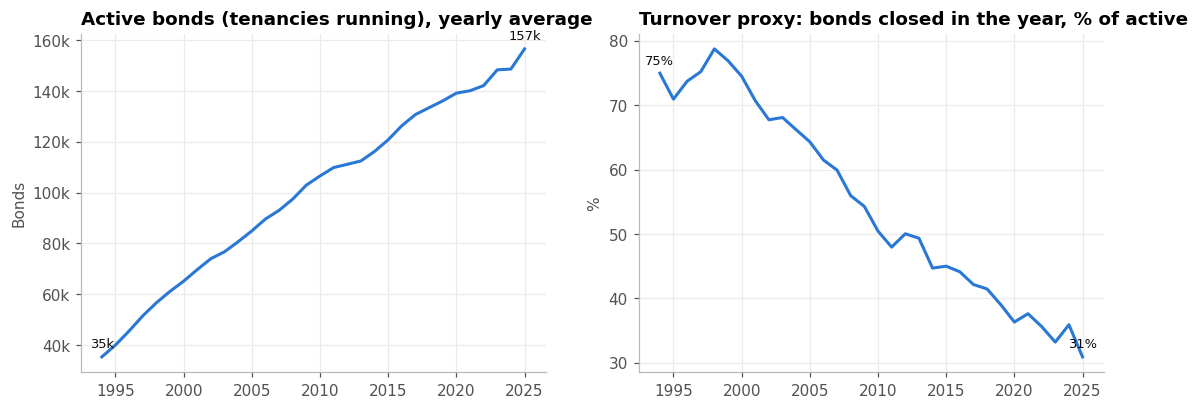

Active bonds 1994 -> 2025: 35,298 -> 156,519 (4.4x)


,active,lodged,closed,turnover_pct
month,,,,
2018,133391.0,57582,55305,41.5
2019,136052.5,56511,53103,39.0
2020,139111.5,52794,50532,36.3
2021,140052.2,52590,52680,37.6
2022,142075.0,55875,50616,35.6
2023,148287.0,53118,49239,33.2
2024,148579.0,53019,53349,35.9
2025,156518.8,65580,48375,30.9


In [7]:
# STEP 6: SIZE (active bonds = tenancies running) and a TURNOVER PROXY (bonds closed in a year / average active bonds)
y = akl.resample('YE').agg({'active': 'mean', 'closed': 'sum', 'lodged': 'sum'})
y = y[(y.index.year > akl.index.min().year) & (y.index.year < akl.index.max().year)]; y.index = y.index.year
y['turnover_pct'] = 100 * y.closed / y.active
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(y.index, y.active, color=BLUE, lw=2); axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v/1e3:.0f}k'))
axes[0].set(title='Active bonds (tenancies running), yearly average', ylabel='Bonds')
axes[1].plot(y.index, y.turnover_pct, color=BLUE, lw=2)
axes[1].set(title='Turnover proxy: bonds closed in the year, % of active', ylabel='%')
for ax, col, fmt in [(axes[0], 'active', lambda v: f'{v/1e3:.0f}k'), (axes[1], 'turnover_pct', lambda v: f'{v:.0f}%')]:
    for yv in [y.index[0], y.index[-1]]:
        ax.annotate(fmt(y.loc[yv, col]), (yv, y.loc[yv, col]), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=8.5, color=INK)
fig.savefig(VIZ / '05_market_size_turnover.png'); plt.show()
print(f'Active bonds {y.index[0]} -> {y.index[-1]}: {y.active.iloc[0]:,.0f} -> {y.active.iloc[-1]:,.0f} ({y.active.iloc[-1]/y.active.iloc[0]:.1f}x)')
y[['active', 'lodged', 'closed', 'turnover_pct']].tail(8).round(1)

**Reading this:**
- The rental market is **4.4 times its 1994 size** (35k to 157k tenancies running).
- **The turnover proxy fell from 75% to 31%** a year: bond closures in the year divided by the average number of active bonds.
  It is consistent with longer tenancies, but it is not a measure of tenancy length, so no average duration is claimed here.
- **2025 is unusual.** New bonds jumped to 65,600 (about 53,000 a year before) and active bonds rose by 8,000 in a year, while
  rent went flat. This data doesn't show why (more homes offered, tenants moving more, or both), so no supply-versus-demand
  conclusion is drawn.

### Step 7: SA2s, turnover and rent spread

In [8]:
# STEP 7: SA2 TURNOVER and RENT SPREAD from the raw quarterly file (last 4 quarters, all dwellings)
geo = gpd.read_file('data/boundaries/auckland_sa2_2023.geojson'); geo['sa2_code'] = geo['SA22023_V1_00'].astype(int)
# MBIE source SA2 for each 2023 SA2, carried from build_master.py (rent_source_sa2)
link = pd.read_csv(CLEAN / 'master_flagged.csv', usecols=['sa2_code', 'rent_source_sa2']).rename(columns={'rent_source_sa2': 'sa2_2018'})

q = pd.read_csv('data/rental/mbie_quarterly_sa2_2020_2026.csv', dtype=str)
q = q[(q['Dwelling Type'] == 'ALL') & (q['Number Of Beds'] == 'ALL')]
q = pd.DataFrame({'quarter': pd.to_datetime(q.TimeFrame, dayfirst=True), 'sa2_2018': pd.to_numeric(q['Location Id'], errors='coerce'),
                  **{k: pd.to_numeric(q[v], errors='coerce') for k, v in
                     {'lodged': 'Total Bonds', 'active': 'Active Bonds', 'closed': 'Closed Bonds', 'uq': 'Upper Quartile Rent', 'lq': 'Lower Quartile Rent'}.items()}})
q = q[q.sa2_2018.isin(link.sa2_2018) & (q.quarter > latest_q - pd.DateOffset(years=1))]
s2 = q.groupby('sa2_2018').agg(closed_4q=('closed', 'sum'), active_avg=('active', 'mean'), lodged_4q=('lodged', 'sum'),
                              uq=('uq', 'mean'), lq=('lq', 'mean'), quarters=('quarter', 'size'))
s2['turnover_pct'] = 100 * s2.closed_4q / s2.active_avg
s2['rent_spread'] = s2.uq / s2.lq
s2 = s2[s2.quarters == 4]   # a full year only, so turnover isn't understated

m = pd.read_csv(CLEAN / 'master_flagged.csv')
area = pd.read_csv(CLEAN / 'area_profiles_by_sa2.csv', usecols=['sa2_code', 'area_type'])
m = m.merge(area, on='sa2_code').merge(link, on='sa2_code', how='left').join(s2[['turnover_pct', 'rent_spread', 'lodged_4q']], on='sa2_2018')
assert len(m) == 633 and m.sa2_code.is_unique
ready = m[m.analysis_ready]
uniq = ready.dropna(subset=['turnover_pct']).drop_duplicates('sa2_2018')   # one row per rental market (borrowed rent shown once)
print(f'SA2 rental markets with a full year: {len(uniq)} | median turnover {uniq.turnover_pct.median():.0f}% | median spread {uniq.rent_spread.median():.2f}')
c = ['sa2_name', 'area_type', 'median_rent_weekly', 'active_bonds', 'turnover_pct', 'rent_spread']
print('Highest and lowest turnover:')
pd.concat([uniq.nlargest(6, 'turnover_pct')[c], uniq.nsmallest(6, 'turnover_pct')[c]]).round(2)

SA2 rental markets with a full year: 479 | median turnover 26% | median spread 1.31
Highest and lowest turnover:


,sa2_name,area_type,median_rent_weekly,active_bonds,turnover_pct,rent_spread
77,Onetangi,Older & coastal,430.75,72.0,63.16,2.35
619,Queen Street South West,Apartments & inner city,448.75,867.0,54.47,1.56
542,Grafton,Apartments & inner city,300.00,516.0,53.65,1.74
620,The Strand,Apartments & inner city,403.00,540.0,52.71,1.56
628,Symonds Street East,Apartments & inner city,458.25,969.0,52.05,1.24
93,Ostend,Older & coastal,678.25,87.0,49.56,1.63
345,Point England North,Crowded family suburbs,534.75,1278.0,10.92,3.90
178,Ōtara Central,Crowded family suburbs,569.00,189.0,13.01,2.57
203,Glen Innes East-Wai O Taiki Bay,Middle suburbs,645.00,831.0,14.57,2.30
229,Green Bay South,Older & coastal,615.00,168.0,14.61,1.28


In [9]:
print('By area type (median across SA2 rental markets):')
uniq.groupby('area_type')[['turnover_pct', 'rent_spread', 'median_rent_weekly']].median().sort_values('turnover_pct', ascending=False).round(2)

By area type (median across SA2 rental markets):


,turnover_pct,rent_spread,median_rent_weekly
area_type,,,
Apartments & inner city,40.39,1.37,492.50
Affluent established suburbs,28.67,1.53,775.25
Older & coastal,27.73,1.30,680.62
Outer suburbs & lifestyle blocks,26.16,1.32,736.25
Middle suburbs,25.69,1.27,653.12
Crowded family suburbs,24.84,1.23,642.50


**Reading this:**
- Turnover here is the same proxy (bond closures over 4 quarters ÷ average active bonds).
- **Check:** the bond-weighted turnover across these SA2 markets is 28.3%, against 27.9% for Auckland from the official monthly series
  over the same 12 months, so the SA2 build reconciles with the total.
- **Apartments & inner city turn over fastest (40%)**: students and short stays. **Crowded family suburbs are the slowest (25%)**:
  families stay put.
- **Extremes:**
  - Onetangi on Waiheke (63%) is a small, holiday-style market with only 72 bonds.
  - Grafton and the CBD SA2s sit at 52–54%.
  - Point England North is the lowest (11%), inside the Tāmaki regeneration area. Its rent spread of 3.9 (upper quartile almost
    4 times the lower) is an outlier that mixes old and newly built homes.
- **Rent spread** (upper / lower quartile) is widest in affluent established suburbs (1.53): a wide mix of houses. It is narrowest in
  crowded family suburbs (1.23): more uniform housing.

**Why an investor cares:** high turnover means more vacant weeks and letting costs, but more chances to reset the rent to market.
Low turnover means steadier income, with rents that lag the market.

### Step 8: Boom and cooling by area type

SA2 rental markets compared: 507


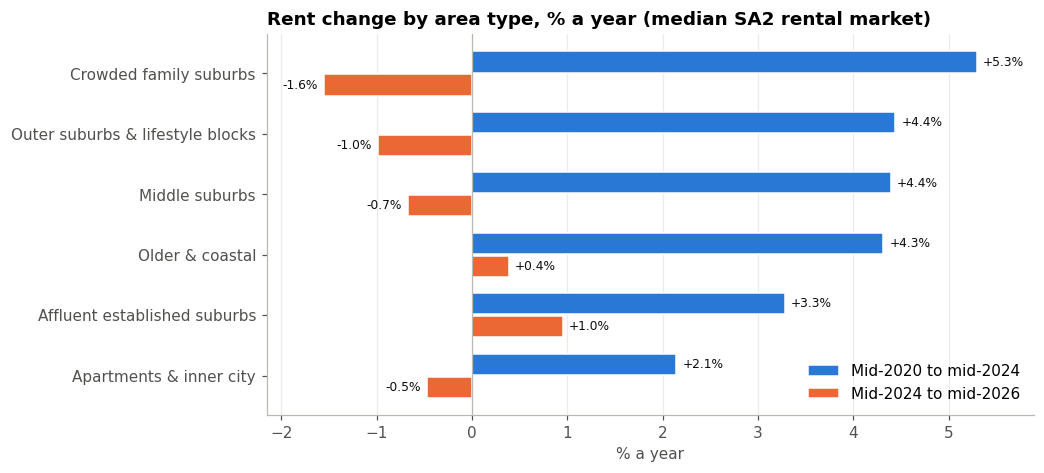

,boom_pa,cooling_pa
area_type,,
Apartments & inner city,2.14,-0.47
Affluent established suburbs,3.28,0.95
Older & coastal,4.31,0.39
Middle suburbs,4.40,-0.67
Outer suburbs & lifestyle blocks,4.44,-0.99
Crowded family suburbs,5.30,-1.55


In [10]:
# STEP 8: WHO LED THE RISE AND WHO COOLED. 4-quarter mean rent at three points, annualised so the periods compare:
#   boom    = year ending 6 years before the latest quarter (mid-2020) -> year ending 2 years before (mid-2024)
#   cooling = mid-2024 -> latest
def window_mean(years_back):
    end = latest_q - pd.DateOffset(years=years_back)
    w = ts[(ts.quarter > end - pd.DateOffset(years=1)) & (ts.quarter <= end)]
    return w.groupby('sa2_code').median_rent.mean()
w = pd.DataFrame({'r_6': window_mean(6), 'r_2': window_mean(2), 'r_0': window_mean(0)})
w['boom_pa'] = 100 * ((w.r_2 / w.r_6) ** (1 / 4) - 1)
w['cooling_pa'] = 100 * ((w.r_0 / w.r_2) ** (1 / 2) - 1)
m = m.join(w[['boom_pa', 'cooling_pa']], on='sa2_code')
uniq = m[m.analysis_ready].dropna(subset=['boom_pa', 'cooling_pa']).drop_duplicates('rent_source_sa2')
bt = uniq.groupby('area_type')[['boom_pa', 'cooling_pa']].median().sort_values('boom_pa')
print(f'SA2 rental markets compared: {len(uniq)}')

fig, ax = plt.subplots(figsize=(9, 4.5))
yy = np.arange(len(bt)); hgt = 0.38
for off, col, colour, label in [(hgt / 2, 'boom_pa', BLUE, f'Mid-{latest_q.year - 6} to mid-{latest_q.year - 2}'),
                                (-hgt / 2, 'cooling_pa', ORANGE, f'Mid-{latest_q.year - 2} to mid-{latest_q.year}')]:
    ax.barh(yy + off, bt[col], height=hgt - 0.03, color=colour, edgecolor='white', linewidth=1, label=label)
    for yv, v in zip(yy + off, bt[col]):
        ax.annotate(f'{v:+.1f}%', (v, yv), xytext=(4 if v >= 0 else -4, 0), textcoords='offset points',
                    ha='left' if v >= 0 else 'right', va='center', fontsize=8, color=INK)
ax.set_yticks(yy, bt.index); ax.axvline(0, color=GREY, lw=0.8); ax.grid(axis='y', visible=False)
ax.set_xlim(bt.min().min() - 0.6, bt.max().max() + 0.6)   # room for the end labels
ax.legend(frameon=False, loc='lower right')
ax.set(title='Rent change by area type, % a year (median SA2 rental market)', xlabel='% a year')
fig.savefig(VIZ / '05_boom_cooling_by_type.png'); plt.show()
bt.round(2)

**Reading this:**
- **Boom (mid-2020 to mid-2024):** every area type rose. **Crowded family suburbs rose fastest (+5.3% a year)** and apartments slowest
  (+2.1%), because the inner city lost students and new migrants while the border was shut.
- **Cooling (since mid-2024):** **the areas that rose most are falling most.** Crowded family suburbs are down 1.5% a year, outer and
  middle suburbs are down 0.7–1.0%, while affluent suburbs (+1.0%) and older & coastal areas (+0.4%) are still edging up.
  The cheap end was the most stretched (File 2: rent above 30% of income) and gave way first.
- **Note for File 4:** its top 20 are mostly South Auckland, partly *because* of strong 10-year rent growth. That growth is reversing
  right now. Treat the growth score as history, not a forecast.

*Caveats:*
- These are medians across SA2 rental markets (one per MBIE source SA2, 507 markets).
- The cooling window is only 2 years.
- Medians of new bonds can shift if the mix of homes let changes.

### Step 9: Sale prices next to rent (HUD, Auckland-wide)

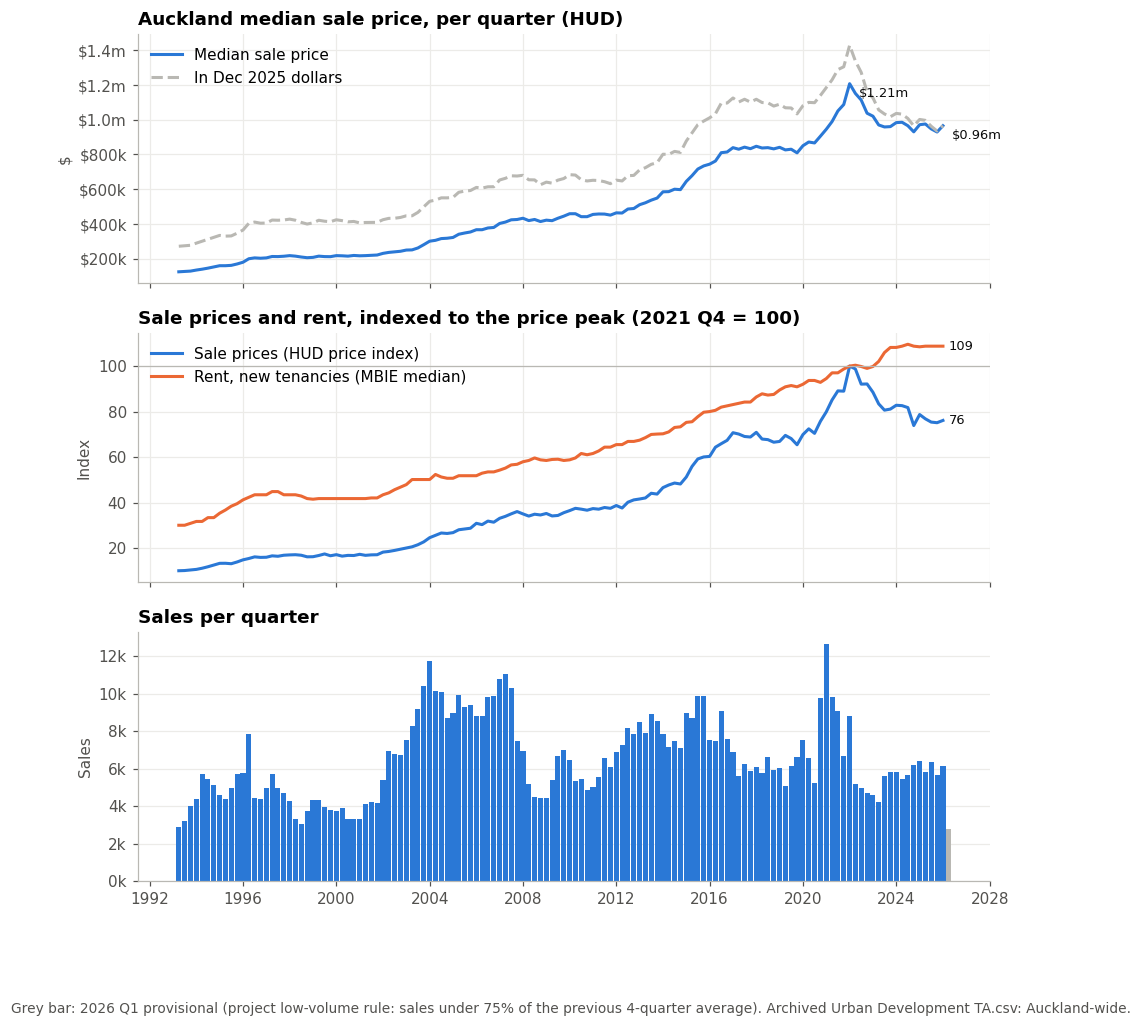

Latest complete quarter 2025 Q4: median $965,000, 6,119 sales | provisional: 2026 Q1
Peak 2021 Q4: median $1,207,000. Since then: median -20.0%, price index -23.9%, real median -32.4% | rent +8.8% (to 2025 Q4)
Price index 1993-2025: 6.4% a year
Sales per year: 2019: 25.3k, 2020: 34.2k, 2021: 34.3k, 2022: 19.4k, 2023: 21.4k, 2024: 23.6k, 2025: 23.9k | lowest year 2000 (13.8k)


,median_sale_price,median_sale_price_real,hpi,sales_count,provisional
quarter_end,,,,,
2024-12-31,971000.0,1.001179e+06,7.699699,6375.0,False
2025-03-31,975000.0,9.960162e+05,7.515011,5790.0,False
2025-06-30,947000.0,9.622274e+05,7.375259,6329.0,False
2025-09-30,929000.0,9.346346e+05,7.348868,5657.0,False
2025-12-31,965000.0,9.650000e+05,7.446650,6119.0,False
2026-03-31,940000.0,NaN,7.098801,2754.0,True


In [11]:
# STEP 9: SALE PRICES from HUD's Urban Development dataset (Auckland territorial authority, quarterly, from 1993).
# The archived Urban Development TA.csv used here is Auckland-wide (one row per council per quarter). Rows dated mid-quarter
# are empty and dropped. (The ministry's separate Property and Sales Statistics dashboard and HPI do cover local boards; not used here.)
import zipfile
with zipfile.ZipFile('data/property_prices/hud_ta_sales_rents.zip').open('data_download/TA.csv') as f:
    hud = pd.read_csv(f, parse_dates=['Date'])
sales = (hud[hud.NAME == 'Auckland'].dropna(subset=['Median_SP']).set_index('Date').sort_index()
         [['Median_SP', 'Median_SP_Real', 'Fisher_PI', 'Quantity']]
         .rename(columns={'Median_SP': 'median_sale_price', 'Median_SP_Real': 'median_sale_price_real',
                          'Fisher_PI': 'hpi', 'Quantity': 'sales_count'}))
sales.index.name = 'quarter_end'
assert sales.index.is_unique and sales.index.is_quarter_end.all()
# Project low-volume rule: the latest quarter is marked provisional when its sales count is under 75% of the previous 4 quarters'
# average (a sign it is incomplete, not a flag published by HUD)
low = sales.sales_count < 0.75 * sales.sales_count.rolling(4).mean().shift(1)
sales['provisional'] = low & (sales.index == sales.index.max())
done = sales[~sales.provisional]
latest, real_base = done.index.max(), sales.median_sale_price_real.dropna().index.max()
assert sales.loc[real_base, 'median_sale_price_real'] == sales.loc[real_base, 'median_sale_price']   # real = in that quarter's dollars

# Rent on the same footing: quarterly mean of MBIE's official monthly medians; both indexed to the price peak
peak = done.hpi.idxmax()
rent_q = akl.median_rent.resample('QE').mean()
idx = pd.DataFrame({'Sale prices (HUD price index)': 100 * done.hpi / done.hpi[peak],
                    'Rent, new tenancies (MBIE median)': 100 * rent_q / rent_q[peak]}).dropna()

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
ax = axes[0]
ax.plot(done.index, done.median_sale_price, color=BLUE, lw=2, label='Median sale price')
ax.plot(done.index, done.median_sale_price_real, color=GREY, lw=2, ls='--', label=f'In {real_base:%b %Y} dollars')
ax.yaxis.set_major_formatter(dollars); ax.legend(frameon=False, loc='upper left')
for when in [peak, latest]:
    v = sales.loc[when, 'median_sale_price']
    ax.annotate(f'${v/1e6:.2f}m', (when, v), xytext=(6, -2), textcoords='offset points', ha='left', va='top', fontsize=8.5, color=INK)
ax.set(title='Auckland median sale price, per quarter (HUD)', ylabel='$')
ax = axes[1]
for (name, s), colour in zip(idx.items(), [BLUE, ORANGE]):
    ax.plot(s.index, s, color=colour, lw=2, label=name)
    ax.annotate(f'{s.iloc[-1]:.0f}', (s.index[-1], s.iloc[-1]), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8.5, color=INK)
ax.axhline(100, color=GREY, lw=0.8); ax.legend(frameon=False, loc='upper left')
ax.set(title=f'Sale prices and rent, indexed to the price peak ({peak.year} Q{peak.quarter} = 100)', ylabel='Index')
ax = axes[2]
ax.bar(sales.index, sales.sales_count, width=80, color=np.where(sales.provisional, GREY, BLUE), linewidth=0)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v/1e3:.0f}k')); ax.grid(axis='x', visible=False)
ax.set(title='Sales per quarter', ylabel='Sales')
fig.text(0.01, -0.01, f'Grey bar: {sales.index.max().year} Q{sales.index.max().quarter} provisional (project low-volume rule: sales under 75% of the previous 4-quarter average). '
         'Archived Urban Development TA.csv: Auckland-wide.', color=MUTED, fontsize=9)
fig.savefig(VIZ / '05_sale_prices.png'); plt.show()

L, P = sales.loc[latest], sales.loc[peak]
yr_sales = done.sales_count.groupby(done.index.year).agg(['sum', 'size']).query('size == 4')['sum']
print(f'Latest complete quarter {latest.year} Q{latest.quarter}: median ${L.median_sale_price:,.0f}, {L.sales_count:,.0f} sales | '
      f'provisional: {", ".join(f"{d.year} Q{d.quarter}" for d in sales.index[sales.provisional]) or "none"}')
print(f'Peak {peak.year} Q{peak.quarter}: median ${P.median_sale_price:,.0f}. Since then: median {100*(L.median_sale_price/P.median_sale_price-1):+.1f}%, '
      f'price index {100*(L.hpi/P.hpi-1):+.1f}%, real median {100*(L.median_sale_price_real/P.median_sale_price_real-1):+.1f}% | '
      f'rent {idx.iloc[-1, 1] - 100:+.1f}% (to {idx.index[-1].year} Q{idx.index[-1].quarter})')
n = yr_sales.index[-1] - yr_sales.index[0]
print(f'Price index {yr_sales.index[0]}-{yr_sales.index[-1]}: {100*((done.hpi[done.index.year == yr_sales.index[-1]].mean() / done.hpi[done.index.year == yr_sales.index[0]].mean())**(1/n)-1):.1f}% a year')
print('Sales per year:', ', '.join(f'{y}: {v/1e3:.1f}k' for y, v in yr_sales.tail(7).items()),
      f'| lowest year {yr_sales.idxmin()} ({yr_sales.min()/1e3:.1f}k)')
sales.tail(6)


**Reading this:**
- **Prices peaked in 2021 Q4 at a \$1,207,000 median and have fallen about a fifth since:** \$965,000 in 2025 Q4 (−20%;
  HUD's price index −24%). In real terms (Dec 2025 dollars) the fall is about a third (−32%).
- **Rent did not follow.** Indexed to the price peak (= 100), rent for new tenancies stood at 109 in 2025 Q4 (+8.8%), the price
  index at 76. Price and rent have moved apart since 2021.
- **Volume collapsed in 2022:** 19.4k sales against 34.3k in 2021, and it has recovered only to about 24k a year (2024–25), close
  to the long-run norm.
- Over 1993–2025 the price index rose 6.4% a year, faster than rent (3.9% a year over 1994–2025, Step 2).

*Caveats:*
- **The archived Urban Development `TA.csv` used here is Auckland-wide** (by territorial authority), so this section has no
  suburb, SA2 or local-board split. The ministry's separate Property and Sales Statistics dashboard and its downloadable HPI
  (MCERT HPI, from August 2026) do cover Auckland local boards; they are not used here. Use CVs (`median_cv_2024`) to compare SA2s.
- The median sale price moves with the mix of homes sold (more apartments sold → lower median). The price index is the better
  trend measure; the median is the better "typical price" figure.
- The newest quarter (2026 Q1, 2,754 sales, under half the usual) is marked **provisional** by the project's low-volume rule (sales under 75% of the previous four quarters' average), which suggests it is incomplete.
  It is saved with `provisional = True` and left out of every figure above.
- HUD's sales data runs to March 2026, MBIE's rent to September 2026, so the two latest points are six months apart.


### Step 10: Save outputs

In [12]:
# STEP 10: SAVE
out1 = CLEAN / 'auckland_rent_monthly.csv'
akl.to_csv(out1, date_format='%Y-%m-%d')
out2 = CLEAN / 'rent_market_by_sa2.csv'
keep = ['sa2_code', 'sa2_name', 'area_type', 'turnover_pct', 'rent_spread', 'lodged_4q', 'boom_pa', 'cooling_pa', 'rent_source_sa2', 'flag_borrowed_rent', 'analysis_ready']
m[keep].round(2).to_csv(out2, index=False)
out3 = CLEAN / 'auckland_sales_quarterly.csv'
sales.round(4).to_csv(out3, date_format='%Y-%m-%d')
c1, c2, c3 = pd.read_csv(out1), pd.read_csv(out2), pd.read_csv(out3)
assert len(c1) == len(akl) and len(c2) == 633 and c2.sa2_code.is_unique and len(c3) == len(sales)
print(f'Saved {out1} ({len(c1)} months), {out2} ({len(c2)} rows) and {out3} ({len(c3)} quarters)')
print('Charts:', ', '.join(sorted(p.name for p in VIZ.glob('05_*.png'))))

Saved data\clean\auckland_rent_monthly.csv (404 months), data\clean\rent_market_by_sa2.csv (633 rows) and data\clean\auckland_sales_quarterly.csv (133 quarters)
Charts: 05_boom_cooling_by_type.png, 05_covid.png, 05_market_size_turnover.png, 05_rent_growth_by_year.png, 05_rent_long_run.png, 05_sale_prices.png, 05_seasonality.png


# File 5: Rent Trends - Summary

## Key findings
| Question | Answer |
|---|---|
| Long-run rent growth | \$200 to \$650/wk, 1994–2025: **3.9% a year** (median year +3.7%) |
| Where it stands now | **\$643/wk**: average of the Jul–Sep 2026 official monthly medians. **Falling slightly**: 2025 −0.1%, 2026 so far −1.1%, the first back-to-back fall since 1998–99 |
| COVID | New bonds −65% in April 2020, back within a month. Rent dipped briefly (\$570 in Apr to \$550 in May 2020), stalled through 2022 and jumped in 2023 after the border reopened |
| Seasonality | Moves peak in Feb–Mar (+17.5%, +9.6% above trend), low in December. Rent itself varies by month by under 1% |
| Market size | 4.4x since 1994 (157k tenancies). **Turnover proxy (bond closures ÷ active bonds) fell from 75% to 31% a year** |
| 2025 | New bonds up about 24% and active bonds up 8,000 while rent was flat; the cause is not in this data |
| SA2 turnover | Apartments & inner city 40%, crowded family suburbs 25%. SA2 totals reconcile with Auckland (28.3% vs 27.9%) |
| Sale prices (HUD, Auckland-wide) | Median **\$965,000** in 2025 Q4, **−20% from the 2021 Q4 peak** (\$1,207,000); price index −24%, real −32%. Rent on new tenancies is 8.8% above its level at the price peak. Sales fell to 19.4k in 2022 (34.3k in 2021), about 24k a year since |
| Boom and cooling | Crowded family suburbs rose most in 2020–24 (+5.3% a year) and are falling most now (−1.5% a year); affluent suburbs still rising (+1.0%) |

## What this changes
- **Dashboard:** use the official monthly median for any Auckland-wide figure. File 1's bond-weighted approximation runs about \$18 high.
- **File 4:** its growth score rewards areas whose rent growth is now reversing. Read it as past performance.
- **Dashboard:** show the HUD sale-price trend next to the rent trend, labelled Auckland-wide. It cannot be split by area.

## Caveats
- Every rent here is for **new** tenancies; sitting tenants pay less, and their rents move later.
- SA2 figures are counted once per MBIE source SA2 (`rent_source_sa2`).
- Turnover is a proxy (closures ÷ active bonds), not tenancy length.
- The archived Urban Development `TA.csv` used here is Auckland-wide; the ministry's local-board HPI (Property and Sales Statistics dashboard) is not used. The newest quarter is provisional under the project's low-volume rule.

## Outputs
- `data/clean/auckland_rent_monthly.csv`: official Auckland monthly series, Feb 1993 – latest (bonds lodged, active, closed; median and quartile rent)
- `data/clean/rent_market_by_sa2.csv`: one row per SA2: turnover, rent spread, bonds lodged over 4 quarters, boom and cooling rates, flags
- `data/clean/auckland_sales_quarterly.csv`: HUD Auckland quarterly median sale price (nominal and real), price index, sales count, `provisional`
- `visualizations/05_*.png`: 7 charts